# Projekt 2 - analiza danych statystycznych (testy statystyczne) 

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
from scipy import stats
from statsmodels.stats.proportion import proportion_confint
from scipy.stats import levene, f_oneway, kruskal, shapiro
from statsmodels.stats.multicomp import pairwise_tukeyhsd


## 1. Wprowadzenie i opis problemu badawczego
**Temat projektu** <br>
Projekt dotyczy statystycznej analizy danych medycznych dotyczących pacjentów, u których zaobserwowano lub nie zaobserwowano wystąpienie udaru mózgu. W odróżnieniu od eksploracyjnej analizy przeprowadzonej w Projekcie 1, celem tego etapu jest weryfikacja hipotez statystycznych dotyczących czynników ryzyka udaru.

**Cel analizy** <br>
Celem projektu jest zastosowanie metod wnioskowania statystycznego - estymacji punktowej i przedziałowej, testów statystycznych, metody bootstrapowej oraz jednoczynnikowej analizy wariancji (ANOVA) - do zbadania zależności między wybranymi cechami klinicznymi i demograficznymi pacjentów a wystąpieniem udaru mózgu.

**Pytania badawcze** <br>
W projekcie podjęto próbę odpowiedzi na następujące pytania badawcze:
- Czy średni wiek pacjentów z udarem mózgu istotnie różni się od średniego wieku pacjentów bez udaru?   <br>(test t-Studenta lub test Manna-Whitneya)
- Czy istnieje statystycznie istotna zależność między paleniem tytoniu a wystąpieniem udaru mózgu? <br>(test chi-kwadrat)
- Czy średni poziom glukozy (avg_glucose_level) we krwi różni się istotnie pomiędzy grupami zawodowymi (work_type)? <br>(jednoczynnikowa ANOVA)
- Jaki jest przedział ufności dla odsetka pacjentów z udarem mózgu w populacji? <br>(estymacja przedziałowa proporcji)

**Źródło danych** <br>
Dane pochodzą z publicznie dostępnego zbioru opublikowanego na platformie Kaggle: <br>Stroke Prediction Dataset <br>Źródło: *https://www.kaggle.com/datasets/fedesoriano/stroke-prediction-dataset*

**Znaczenie analizowanego problemu** <br>
Udar mózgu stanowi jedno z najpoważniejszych zagrożeń zdrowotnych na świecie. Według Światowej Organizacji Zdrowia, udar jest trzecią najczęstszą przyczyną zgonów i niepełnosprawności na świecie. Wczesna identyfikacja czynników ryzyka - takich jak wiek, poziom glukozy, nadciśnienie czy styl życia - może przyczynić się do lepszgo zapobiegania, czy wcześniejszej interwencji medycznej. Formalna weryfikacja statystyczna tych zależności nadaje wynikom obiektywny charakter i pozwala ocenić ich istotność w sensie statystycznym.

## 2. Opis danych

In [2]:
df=pd.read_csv("healthcare-dataset-stroke-data.csv")
df.head()

,id,gender,age,hypertension,heart_disease,ever_married,work_type,Residence_type,avg_glucose_level,bmi,smoking_status,stroke
0,9046,Male,67.0,0,1,Yes,Private,Urban,228.69,36.6,formerly smoked,1
1,51676,Female,61.0,0,0,Yes,Self-employed,Rural,202.21,NaN,never smoked,1
2,31112,Male,80.0,0,1,Yes,Private,Rural,105.92,32.5,never smoked,1
3,60182,Female,49.0,0,0,Yes,Private,Urban,171.23,34.4,smokes,1
4,1665,Female,79.0,1,0,Yes,Self-employed,Rural,174.12,24.0,never smoked,1


**Liczba obserwacji i zmiennych**
- Liczba obserwacji: 5110
- Liczba zmiennych: 12 

In [3]:
print(f"Liczba wierszy: {df.shape[0]}")
print(f"Liczba kolumn: {df.shape[1]}")

Liczba wierszy: 5110
Liczba kolumn: 12


**Opis i typy zmiennych**

In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 5110 entries, 0 to 5109
Data columns (total 12 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   id                 5110 non-null   int64  
 1   gender             5110 non-null   str    
 2   age                5110 non-null   float64
 3   hypertension       5110 non-null   int64  
 4   heart_disease      5110 non-null   int64  
 5   ever_married       5110 non-null   str    
 6   work_type          5110 non-null   str    
 7   Residence_type     5110 non-null   str    
 8   avg_glucose_level  5110 non-null   float64
 9   bmi                4909 non-null   float64
 10  smoking_status     5110 non-null   str    
 11  stroke             5110 non-null   int64  
dtypes: float64(3), int64(4), str(5)
memory usage: 634.7 KB


In [5]:
zm_jakosciowe = [
    "gender", "hypertension", "heart_disease",
    "ever_married", "work_type", "Residence_type",
    "smoking_status", "stroke"
]

zm_ilosciowe = ["age", "avg_glucose_level", "bmi"]

print("\n Zmienne jakościowe")
for col in zm_jakosciowe:
    print(f"\nZmienna: {col}")
    print(f"Kardynalność: {df[col].nunique()}")
    print(f"Uniklane wartości: {df[col].unique()}")

print("\nZmienne ilościowe")
print(df[zm_ilosciowe].describe())


 Zmienne jakościowe

Zmienna: gender
Kardynalność: 3
Uniklane wartości: <ArrowStringArray>
['Male', 'Female', 'Other']
Length: 3, dtype: str

Zmienna: hypertension
Kardynalność: 2
Uniklane wartości: [0 1]

Zmienna: heart_disease
Kardynalność: 2
Uniklane wartości: [1 0]

Zmienna: ever_married
Kardynalność: 2
Uniklane wartości: <ArrowStringArray>
['Yes', 'No']
Length: 2, dtype: str

Zmienna: work_type
Kardynalność: 5
Uniklane wartości: <ArrowStringArray>
['Private', 'Self-employed', 'Govt_job', 'children', 'Never_worked']
Length: 5, dtype: str

Zmienna: Residence_type
Kardynalność: 2
Uniklane wartości: <ArrowStringArray>
['Urban', 'Rural']
Length: 2, dtype: str

Zmienna: smoking_status
Kardynalność: 4
Uniklane wartości: <ArrowStringArray>
['formerly smoked', 'never smoked', 'smokes', 'Unknown']
Length: 4, dtype: str

Zmienna: stroke
Kardynalność: 2
Uniklane wartości: [1 0]

Zmienne ilościowe
               age  avg_glucose_level          bmi
count  5110.000000        5110.000000  4909.0

| Zmienna | Typ  | Kardynalność | Jednostka | Opis | Kategorie / Uwagi |
|---|---|---|---|---|---|
| `gender` | jakościowa nominalna | 3 | - | Płeć pacjenta | Male, <br>Female, <br>Other\*\*\* |
| `hypertension` | jakościowa dychotomiczna | 2 | - | Występowanie nadciśnienia tętniczego | 0=brak, <br>1=nadciśnienie |
| `heart_disease` | jakościowa dychotomiczna | 2 | - | Występowanie choroby serca | 0=brak, <br>1=choroba serca |
| `ever_married` | jakościowa dychotomiczna | 2 | - | Czy pacjent był kiedykolwiek w związku małżeńskim | Yes, No |
| `work_type` | jakościowa nominalna | 5 | - | Typ zatrudnienia pacjenta | Private, <br>Self-employed, <br>Govt_job, <br>children, <br>Never_worked |
| `Residence_type` | jakościowa dychotomiczna | 2 | - | Typ miejsca zamieszkania | Urban, Rural |
| `smoking_status` | jakościowa nominalna | 4 | - | Status palenia tytoniu | never smoked, <br>formerly smoked, <br>smokes, <br>Unknown\*\* |
| `stroke` | jakościowa dychotomiczna | 2 | - | Wystąpienie udaru mózgu |zmienna targetowa: <br>0=brak udaru, <br>1=udar |
| `age` | ilościowa | - | lata | Wiek pacjenta | - |
| `avg_glucose_level` | ilościowa | - | mg/dL* | Średni poziom glukozy we krwi | - |
| `bmi` | ilościowa | - | kg/m²* | Wskaźnik masy ciała | występują braki |

*\*\*\* Kategoria Other występuje tylko w 1 obserwacji - zostanie usunięta na etapie przygotowania danych.*  
*\*\* Unknown nie jest technicznym NaN, lecz osobną kategorią oznaczającą brak informacji o statusie palenia.*  
*\* Jednostki nie zostały podane w źródle - wynikają z definicji wskaźnika (BMI) lub skali wartości (glukoza).*

W zbiorze danych nie zidentyfikowano wartości nietypowych/podejrzanych.

**Braki danych**

In [6]:
braki = df.isnull().sum()
braki_proc = (braki / len(df) * 100).round(2)
print(pd.DataFrame({"Braki": braki, "% braków": braki_proc}))

                   Braki  % braków
id                     0      0.00
gender                 0      0.00
age                    0      0.00
hypertension           0      0.00
heart_disease          0      0.00
ever_married           0      0.00
work_type              0      0.00
Residence_type         0      0.00
avg_glucose_level      0      0.00
bmi                  201      3.93
smoking_status         0      0.00
stroke                 0      0.00


W zbiorze braki danych występują tylko w zmiennej bmi - łącznie 201 obserwacji (3,93%) zawiera wartość brakującą (NaN).<br>
Pozostałe zmienne nie zawierają brakujących wartości w sensie technicznym, ale należy jednak zaznaczyć, że zmienna smoking_status zawiera kategorię "Unknown", która oznacza brak informacji o statusie palenia - nie jest to wartość NaN, ale powinna być traktowana ostrożnie przy analizach tej zmiennej.

**Przygotowanie danych do analizy**<br>
Przygotowanie danych obejmuje następujące kroki:
1. **Usunięcie obserwacji `gender = "Other"`**: jedyna taka obserwacja nie pozwala na żadne wnioskowanie statystyczne dla tej kategorii i zostaje usunięta (po tej operacji zbiór będzie liczył 5 109 obserwacji).
2. **Obsługa braków w `bmi`**: Zmienna zawiera 201 braków (3,93% obserwacji). W Projekcie 1 wykazano, że braki nie mają charakteru w pełni losowego - pacjenci z brakującym BMI są przeciętnie starsi i częściej doświadczyli udaru (20% vs. 4%), przez co usunięcie tych wierszy nieproporcjonalnie zmniejszyłoby reprezentację przypadków udaru. Z tego względu zdecydowano o imputacji medianą w grupach płci, która uwzględnia naturalną różnicę w budowie ciała między płciami i jest odporna na wartości odstające. W projekcie nie przewiduje się testów dotyczących zmiennej `bmi`, więc wybór metody imputacji nie ma istotnego wpływu na wyniki analizy.
3. Zmienne kategoryczne pozostają w formacie tekstowym - zostaną zakodowane w przypadku jeśli testy będą tego wymagać.
4. **Usunięcie zmiennej `id`**: identyfikator techniczny nieużywany w analizie (po tej operacji zbiór będzie liczył 11 zmiennych).

In [7]:
# 1. Usunięcie obserwacji gender = "Other"
df = df[df['gender'] != 'Other'].reset_index(drop=True)
print(df['gender'].value_counts())

gender
Female    2994
Male      2115
Name: count, dtype: int64


In [8]:
# 2. Obsługa braków w bmi - imputacja medianą w grupach płci 
print(df.groupby('gender')['bmi'].median().round(1)) # sprawdzenie median
df['bmi'] = df.groupby('gender')['bmi'].transform(lambda x: x.fillna(x.median()))

gender
Female    27.8
Male      28.4
Name: bmi, dtype: float64


In [9]:
# 4. Usunięcie zmiennej id
df = df.drop(columns=['id'])

In [10]:
print(f"Liczba wierszy: {df.shape[0]}")
print(f"Liczba kolumn: {df.shape[1]}")

Liczba wierszy: 5109
Liczba kolumn: 11


## 3. Analiza opisowa danych

**Statystyki opisowe - zmienne numeryczne**

In [11]:
stats_cols = zm_ilosciowe
desc = df[stats_cols].describe().T
desc['median'] = df[stats_cols].median()
desc['IQR'] = desc['75%'] - desc['25%']
display(desc[['mean', 'median', 'std', '25%', '50%','75%', 'min', 'max', 'IQR']].round(2))

,mean,median,std,25%,50%,75%,min,max,IQR
age,43.23,45.00,22.61,25.00,45.00,61.00,0.08,82.00,36.00
avg_glucose_level,106.14,91.88,45.29,77.24,91.88,114.09,55.12,271.74,36.85
bmi,28.86,28.10,7.70,23.80,28.10,32.80,10.30,97.60,9.00


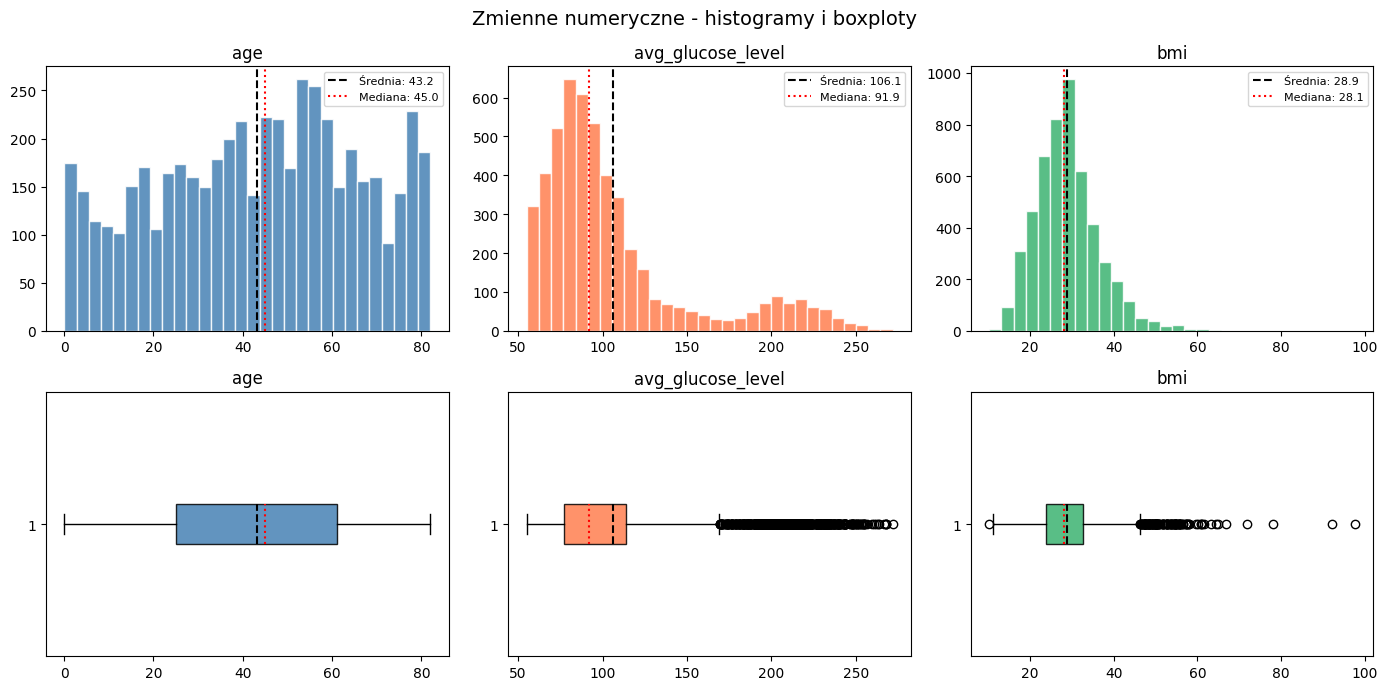

In [12]:
fig, axes = plt.subplots(2, 3, figsize=(14, 7))
fig.suptitle("Zmienne numeryczne - histogramy i boxploty", fontsize=14)

cols = ['age', 'avg_glucose_level', 'bmi']
colors = ['steelblue', 'coral', 'mediumseagreen']

# histogramy
for ax, col, color in zip(axes[0], cols, colors):
    ax.hist(df[col], bins=30, color=color, edgecolor='white', alpha=0.85)
    ax.axvline(df[col].mean(), color='black', linestyle='--', linewidth=1.5, label=f'Średnia: {df[col].mean():.1f}')
    ax.axvline(df[col].median(), color='red', linestyle=':', linewidth=1.5, label=f'Mediana: {df[col].median():.1f}')
    ax.set_title(col)
    ax.legend(fontsize=8)

# boxploty
for ax, col, color in zip(axes[1], cols, colors):
    ax.boxplot(df[col].dropna(), vert=False, patch_artist=True,
               boxprops=dict(facecolor=color, alpha=0.85),
               showmeans=True,  meanline=True,
               meanprops={"color": "black", "linewidth":1.5},
               medianprops={"color": "red", "linestyle":':', "linewidth":1.5})
    ax.set_title(col)

plt.tight_layout()
plt.show()

Interpretacja:
- Wiek: rozkład jest stosunkowo symetryczny (średnia zbliżona do mediany) i równomierny. Pacjenci obejmują szeroki przedział wiekowy - od niemowląt (0,08 lat) do 82 lat. Duże odchylenie standardowe (22,61 lat) potwierdza dużą różnorodność grupy.
- Poziom glukozy: wyraźna różnica między średnią (106,14) a medianą (91,88) wskazuje na prawostronną asymetrię rozkładu - co potwierdza równiez wykres histogrmau. Duża część pacjentów skupia się w przedziale 70-120 mg/dL, ale obserwuje się długi ogon ku wysokim wartościom - pacjenci z wysokimi wartościami glukozy, które zawyżają średnią. Maksimum 271,74 mg/dL zdecydowanie przekracza normę kliniczną, ale wciąż jest to mozliwa wartość.
- BMI: rozkład zbliżony do symetrycznego, z medianą wskazującą na nadwagę (BMI >= 25). Maksimum 97,60 kg/m² to ekstremalna otyłość - wartość klinicznie możliwa.

**Statystyki opisowe - zmienna docelowa stroke**

In [13]:
print(df['stroke'].value_counts())
print(f"\nOdsetek udarów: {df['stroke'].mean()*100:.2f}%")

stroke
0    4860
1     249
Name: count, dtype: int64

Odsetek udarów: 4.87%


Zbiór jest silnie niezbalansowany - przypadki udaru stanowią niecałe 5% obserwacji. Jest to realistyczny obraz epidemiologiczny, ale przy interpretacji wyników testów statystycznych należy mieć na uwadze tę dysproporcję.

**Rozkład zmiennych kategorycznych**

In [14]:
for col in ['gender', 'work_type', 'smoking_status', 'Residence_type']:
    print(f"\n{col}:\n{df[col].value_counts()}")


gender:
gender
Female    2994
Male      2115
Name: count, dtype: int64

work_type:
work_type
Private          2924
Self-employed     819
children          687
Govt_job          657
Never_worked       22
Name: count, dtype: int64

smoking_status:
smoking_status
never smoked       1892
Unknown            1544
formerly smoked     884
smokes              789
Name: count, dtype: int64

Residence_type:
Residence_type
Urban    2596
Rural    2513
Name: count, dtype: int64


**Dodatkowe wykresy**

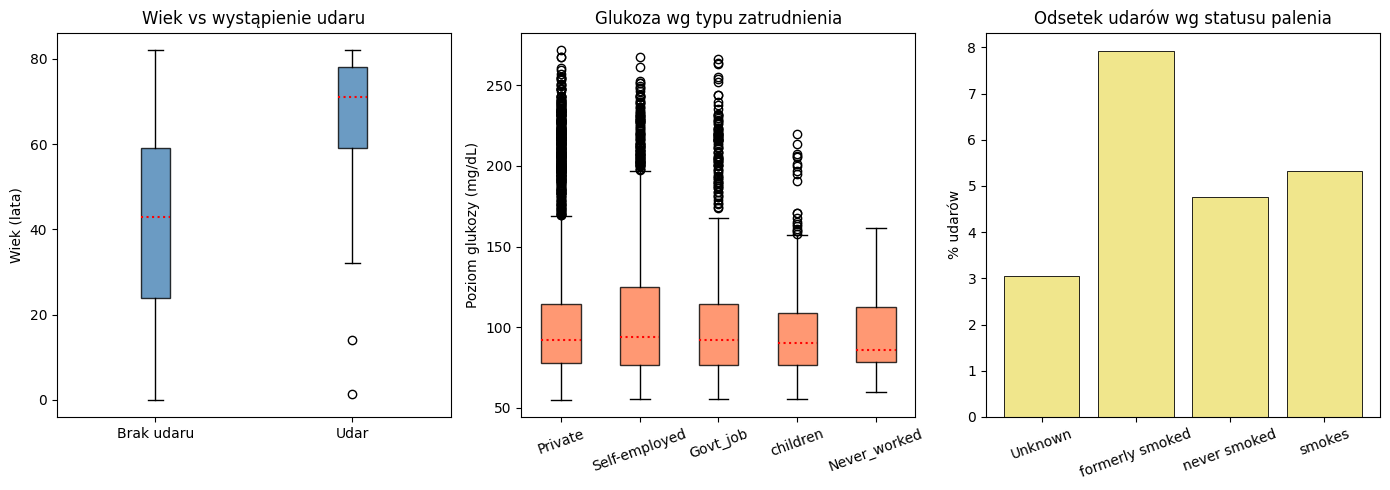

In [15]:
fig, axes = plt.subplots(1, 3, figsize=(14, 5))

# Boxplot: age wg stroke
axes[0].boxplot([df[df['stroke']==0]['age'], df[df['stroke']==1]['age']],
                    tick_labels=['Brak udaru', 'Udar'], patch_artist=True,
                    boxprops=dict(facecolor='steelblue', alpha=0.8),
                    medianprops={"color": "red", "linestyle":':', "linewidth":1.5})
axes[0].set_title("Wiek vs wystąpienie udaru")
axes[0].set_ylabel("Wiek (lata)")

# Boxplot: glucose wg work_type
groups = [df[df['work_type']==wt]['avg_glucose_level'] for wt in df['work_type'].unique()]
axes[1].boxplot(groups, tick_labels=df['work_type'].unique(), patch_artist=True, 
                boxprops=dict(facecolor='coral', alpha=0.8),
                medianprops={"color": "red", "linestyle":':', "linewidth":1.5})
axes[1].set_title("Glukoza wg typu zatrudnienia")
axes[1].set_ylabel("Poziom glukozy (mg/dL)")
axes[1].tick_params(axis='x', rotation=20)

# Wykres słupkowy: odsetek udarów wg smoking_status
stroke_by_smoking = df.groupby('smoking_status')['stroke'].mean() * 100
axes[2].bar(stroke_by_smoking.index, stroke_by_smoking.values, color='khaki', edgecolor='black', linewidth=0.6)
axes[2].set_title("Odsetek udarów wg statusu palenia")
axes[2].set_ylabel("% udarów")
axes[2].tick_params(axis='x', rotation=20)

plt.tight_layout()
plt.show()

Interpretacja wykresów:
- Boxploty - Wiek vs wystąpienie udaru: pacjenci z udarem są wyraźnie starsi (mediana ok. 72 lat) niż pacjenci bez udaru (mediana ok. 44 lata). To wizualne potwierdzenie różnicy, która formalnie zostanie zbadana w sekcji testowania hipotez.
- Boxploty - Glukoza wg typu zatrudnienia: zaobserwowano widoczne różnice w rozkładzie poziomu glukozy między grupami zawodowymi. Osoby samozatrudnione (Self-employed) wykazują wyższe mediany i większe rozrzuty niż dzieci (children). Różnice te zostaną formalnie zbadane testem ANOVA.
- Wykres słupkowy - Odsetek udarów wg statusu palenia: najwyższy odsetek udarów obserwuje się wśród byłych palaczy (formerly smoked), co może wskazywać na związek historii palenia z ryzykiem udaru. Związek ten zostanie zweryfikowany testem chi-kwadrat.

## 4. Estymacja punktowa i przedziałowa

### 4.1 Estymacja punktowa 

Stosowane estymatory:
- średnia - nieobciążony estymator wartości oczekiwanej μ
- wariancja(ddof=1) - nieobciążony estymator wariancji σ² (dzielenie przez n-1 zamiast n, ponieważ dane stanowią próbę, a nie całą populację)
- odchylenie standardowe - estymator σ


In [16]:
# Wiek
n = len(df)
mean_age = df['age'].mean()     
var_age = df['age'].var(ddof=1)   
std_age = df['age'].std(ddof=1)   

# Poziom glukozy 
mean_gluc = df['avg_glucose_level'].mean()
var_gluc = df['avg_glucose_level'].var(ddof=1)
std_gluc = df['avg_glucose_level'].std(ddof=1)

estymacja_punktowa = pd.DataFrame([
    ["Średnia", f"{mean_age:.4f}", f"{mean_gluc:.4f}"],
    ["Wariancja", f"{var_age:.4f}", f"{var_gluc:.4f}"],
    ["Odchylenie std", f"{std_age:.4f}", f"{std_gluc:.4f}"]
], columns=["Estymator", "Wiek", "Poziom glukozy"]
)

display(estymacja_punktowa)


,Estymator,Wiek,Poziom glukozy
0,Średnia,43.2300,106.1404
1,Wariancja,511.3738,2050.7316
2,Odchylenie std,22.6136,45.2850


Estymator frakcji =  liczba sukcesów / wielkosć próby

In [17]:
# Proporcja udarów 
n_stroke = df['stroke'].sum()
total= len(df) 
p = n_stroke / total

print(f"Estymowana proporcja udarów: {p:.4f} ({p*100:.2f}%)")

Estymowana proporcja udarów: 0.0487 (4.87%)


### 4.2 Estymacja przedziałowa 

Przedziały ufności wyznaczono na poziomie ufności 95% (alpha = 0.05).
- Dla średnich zastosowano rozkład normalny bo próba jest duża (n=5109, n>30), więc odchylenie z próby jest wystarczająco dobrym przybliżeniem σ populacji.
- Dla proporcji zastosowano metodę Wilsona.

In [18]:
alpha = 0.05  # poziom istotności

# Przedziały ufności dla średniego wieku 
ci_age = stats.norm.interval(
    confidence=1 - alpha,
    loc=mean_age,
    scale=stats.sem(df['age'])
)

# Przedziały ufności dla średniego poziomu glukozy (ogółem)
ci_gluc = stats.norm.interval(
    confidence=1 - alpha,
    loc=mean_gluc,
    scale=stats.sem(df['avg_glucose_level'])
)

# Przedziały ufności dla średniej glukozy wg grupy stroke 
gluc_no_stroke = df[df['stroke'] == 0]['avg_glucose_level']
gluc_stroke = df[df['stroke'] == 1]['avg_glucose_level']

ci_gluc_0 = stats.norm.interval(1-alpha, loc=gluc_no_stroke.mean(),scale=stats.sem(gluc_no_stroke))
ci_gluc_1 = stats.norm.interval(1-alpha, loc=gluc_stroke.mean(), scale=stats.sem(gluc_stroke))

# Przedziały ufności dla proporcji udarów (metoda Wilsona) 
ci_prop = proportion_confint(count=n_stroke, nobs=n, alpha=alpha, method='wilson')

print("Przedziały ufności (poziom ufności 95%)\n")
print(f"Średni wiek: {mean_age:.2f}, przedział ufności: ({ci_age[0]:.2f} ; {ci_age[1]:.2f})")
print(f"Średnia glukoza (ogółem): {mean_gluc:.2f}, przedział ufności: ({ci_gluc[0]:.2f} ; {ci_gluc[1]:.2f})")
print(f"Średnia glukoza (bez udaru): {gluc_no_stroke.mean():.2f} przedział ufności: ({ci_gluc_0[0]:.2f} ; {ci_gluc_0[1]:.2f})")
print(f"Średnia glukoza (udar): {gluc_stroke.mean():.2f}, przedział ufności: ({ci_gluc_1[0]:.2f} ; {ci_gluc_1[1]:.2f})")
print(f"Proporcja udarów: {p:.4f}, przedział ufności: ({ci_prop[0]:.4f} ; {ci_prop[1]:.4f})")


Przedziały ufności (poziom ufności 95%)

Średni wiek: 43.23, przedział ufności: (42.61 ; 43.85)
Średnia glukoza (ogółem): 106.14, przedział ufności: (104.90 ; 107.38)
Średnia glukoza (bez udaru): 104.79 przedział ufności: (103.55 ; 106.02)
Średnia glukoza (udar): 132.54, przedział ufności: (124.85 ; 140.24)
Proporcja udarów: 0.0487, przedział ufności: (0.0432 ; 0.0550)


Z prawdopodobieństwem 95% prawdziwa średnia wieku pacjentów w populacji zawiera się w przedziale (42,61 ; 43,85) lat. Wąski przedział świadczy o dużej precyzji estymacji, wynikającej z licznej próby. <br>

Średni poziom glukozy w całej próbie mieści się w przedziale (104,90 ; 107,38) mg/dL. Istotną obserwacją jest jednak to, że przedziały ufności dla grup wyodrębnionych według wystąpienia udaru nie zachodzą na siebie tzn. dla pacjentów bez udaru wynosi on (103,55 ; 106,02) mg/dL, natomiast dla pacjentów z udarem (124,85 ; 140,24) mg/dL. Brak nakładania się przedziałów stanowi silną przesłankę wskazującą na istotną różnicę w poziomie glukozy między grupami, która zostanie zweryfikowana w sekcji testowania hipotez. Warto również zauważyć, że przedział dla grupy z udarem jest szerszy, co może wynikać to z mniejszej liczebności tej grupy i przekłada się na mniejszą precyzję estymacji.<br>

Estymowany odsetek udarów w populacji z 95% pewnością mieści się w przedziale (4,32% ; 5,50%). Zastosowano metodę Wilsona zamiast klasycznej metody Walda, ponieważ jest ona zalecana przy małych proporcjach.

## 5. Testowanie hipotez statystycznych

In [19]:

alpha = 0.05  # poziom istotności dla wszystkich testów

def print_result(p_value, alpha=0.05):
    if p_value < alpha:
        return f"p = {p_value:.6f} < alpha = {alpha} -> odrzucenie H0"
    else:
        return f"p = {p_value:.6f} >= alpha = {alpha} -> brak podstaw do odrzucenia H0"

### Test 1: Shapiro-Wilka - normalność rozkładu wieku
Test wstępny przed wyborem testu dla pytania badawczego nr 1<br>
Hipotezy:
- H0​: Rozkład wieku w grupie jest normalny
- H1​: Rozkład wieku w grupie nie jest normalny
Poziom istotności: alpha=0,05

Test Shapiro-Wilka: normalność rozkładu wieku

Grupa bez udaru (n=500): W = 0.969407, p = 0.000000 < alpha = 0.05 -> odrzucenie H0
Grupa z udarem (n=100): W = 0.920860, p = 0.000016 < alpha = 0.05 -> odrzucenie H0


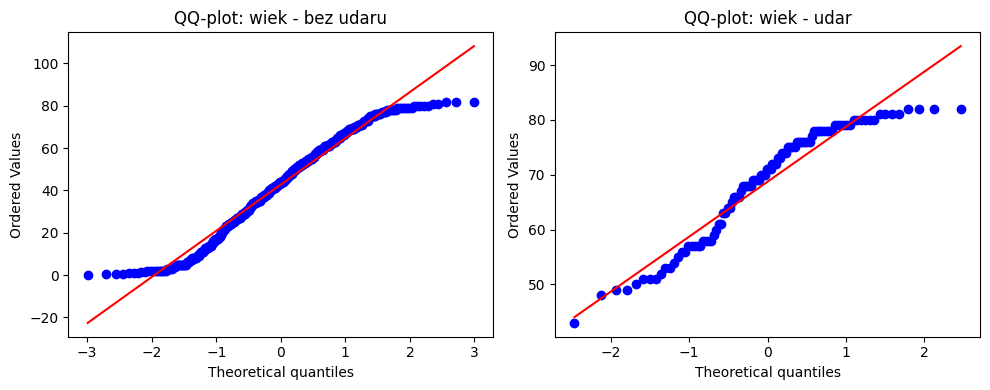

In [20]:
# Próbkowanie losowo bo test Shapiro-Wilka jest ograniczony do n <= 5000, dlatego sprawdzenie na podpróbie.

np.random.seed(42)
sample_no_stroke = df[df['stroke'] == 0]['age'].sample(500)
sample_stroke = df[df['stroke'] == 1]['age'].sample(100)

stat_0, p_0 = stats.shapiro(sample_no_stroke)
stat_1, p_1 = stats.shapiro(sample_stroke)

print("Test Shapiro-Wilka: normalność rozkładu wieku")
print(f"\nGrupa bez udaru (n=500): W = {stat_0:.6f}, {print_result(p_0)}")
print(f"Grupa z udarem (n=100): W = {stat_1:.6f}, {print_result(p_1)}")

# QQ-plot 
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
stats.probplot(sample_no_stroke, dist="norm", plot=axes[0])
axes[0].set_title("QQ-plot: wiek - bez udaru")
stats.probplot(sample_stroke, dist="norm", plot=axes[1])
axes[1].set_title("QQ-plot: wiek - udar")
plt.tight_layout()
plt.show()

Hipoteza zerowa H0 zakłada, że rozkład wieku w badanej grupie jest normalny. Test przeprowadzono na podpróbach (grupa bez udaru: n=500, grupa z udarem: n=100), ponieważ test Shapiro-Wilka jest wrażliwy na bardzo duże liczebności (wówczas nawet minimalne odchylenia od normalności skutkują odrzuceniem H0)​.<br>
W obu grupach uzyskano p-value < 0,05, co oznacza odrzucenie hipotezy o normalności rozkładu. Statystyka W wyniosła ~0,969 dla grupy bez udaru oraz ~0,921 dla grupy z udarem. Obie wartości są bliskie 1, jednak od niej odbiegają, co potwierdza niespełnienie założenia normalności.<br>
Analiza QQ-plotów potwierdza to odchylenie. W grupie bez udaru widoczne jest lekkie esowate wygięcie punktów względem linii odniesienia, wskazujące na spłaszczony rozkład z lekkimi ogonami. W grupie z udarem punkty również odchylają się, co świadczy o lewostronnej asymetrii - pacjenci z udarem są skupieni w wyższych przedziałach wiekowych.<br>
Założenie normalności nie jest spełnione w żadnej z grup, dlatego do porównania rozkładów wieku zastosowany zostanie nieparametryczny test Manna-Whitneya, który nie wymaga tego założenia.

### Test 2: Manna-Whitneya - wiek a udar mózg
Odpowiedź na pytanie badawcze nr 1: *Czy średni wiek pacjentów z udarem mózgu istotnie różni się od średniego wieku pacjentów bez udaru?* <br>
Hipotezy:
- H0​: Rozkłady wieku w grupie z udarem i bez udaru są identyczne (brak różnicy)
- H1​: Rozkłady wieku różnią się między grupami (test dwustronny)
Poziom istotności: alpha=0,05

In [21]:
group_no_stroke = df[df['stroke'] == 0]['age']
group_stroke  = df[df['stroke'] == 1]['age']

stat_mw, p_mw = stats.mannwhitneyu(group_stroke, group_no_stroke, alternative='two-sided')

print(f"Średni wiek bez udaru: {group_no_stroke.mean():.2f} lat (mediana: {group_no_stroke.median():.2f})")
print(f"Średni wiek z udarem:  {group_stroke.mean():.2f} lat (mediana: {group_stroke.median():.2f})")

print("\nTest Manna-Whitneya: wiek a udar mózgu")
print(f"\nStatystyka U = {stat_mw:.4f}")
print(print_result(p_mw))


Średni wiek bez udaru: 41.97 lat (mediana: 43.00)
Średni wiek z udarem:  67.73 lat (mediana: 71.00)

Test Manna-Whitneya: wiek a udar mózgu

Statystyka U = 1009878.5000
p = 0.000000 < alpha = 0.05 -> odrzucenie H0


Wrtość p-value jest poniżej przyjętego poziomu istotności alpha=0,05, zatem hipoteza zerowa H0 zostaje odrzucona. Istnieje statystycznie istotna różnica w rozkładzie wieku między pacjentami z udarem a pacjentami bez udaru. Mediana wieku w grupie z udarem wynosi ~71 lat, wobec ~43 lat w grupie bez udaru . Wynik ten jest spójny z obserwacją z analizy opisowej (sekcja 3), gdzie boxplot wizualnie wskazywał na wyraźną różnicę między grupami. Test Manna-Whitneya potwierdza formalnie to co było już widoczne na wykresie, czyli, że pacjenci z udarem są statystycznie istotnie starsi.

### Test 3: Chi-kwadrat - palenie tytoniu a udar
Odpowiedź na pytanie badawcze nr 2: *Czy istnieje statystycznie istotna zależność między paleniem tytoniu a wystąpieniem udaru mózgu?* <br>
Hipotezy:
- H0​: Status palenia tytoniu i wystąpienie udaru mózgu są niezależne
- H1​: Istnieje zależność między statusem palenia a udarem mózgu
Poziom istotności: alpha=0,05

Kategoria Unknown 

In [22]:
# Sprawdzenie kategorii 'Unknown': czy pacjenci z Unknown różnią się od reszty?

print(df.groupby(df['smoking_status'] == 'Unknown')['stroke'].mean().round(4) * 100)
print(df.groupby(df['smoking_status'] == 'Unknown')['age'].mean().round(2))

unknown = df[df['smoking_status'] == 'Unknown']
unknown['age'].describe()

smoking_status
False    5.67
True     3.04
Name: stroke, dtype: float64
smoking_status
False    48.86
True     30.23
Name: age, dtype: float64


count    1544.000000
mean       30.229922
std        25.055556
min         0.080000
25%         8.000000
50%        23.000000
75%        51.000000
max        82.000000
Name: age, dtype: float64

Analiza wykazała, że pacjenci z kategorią Unknown są przeciętnie młodsi (średnia 30,23 vs 48,86 lat), jednak grupa ta jest bardzo zróżnicowana wiekowo (zakres 0,08-82 lata) - nie są to wyłącznie dzieci. Niższy odsetek udarów w tej grupie (3,04% vs 5,67%) może być po prostu konsekwencją młodszego wieku, a nie brakiem związku palenia z udarem. Usunięcie kategorii Unknown jest zatem uzasadnione - nie reprezentuje ona rzeczywistego statusu palenia, a pacjenci z tej grupy nie różnią się drastycznuie od pozostałych. Wyniki testu dotyczą wyłącznie pacjentów z udokumentowanym statusem palenia, z zaznaczeniem że ze względu na liczebność usuniętej kategorii (n=1544, 30,2% obserwacji) stanowi to ograniczenie analizy.


Tabela kontyngencji: palenie vs. udar
stroke              0   1
smoking_status           
formerly smoked   814  70
never smoked     1802  90
smokes            747  42

Oczekiwane liczebności:
stroke                0      1
smoking_status                
formerly smoked   833.9   50.1
never smoked     1784.8  107.2
smokes            744.3   44.7

Statystyka Chi2 = 11.4906
Stopnie swobody: 2
p = 0.003198 < alpha = 0.05 -> odrzucenie H0


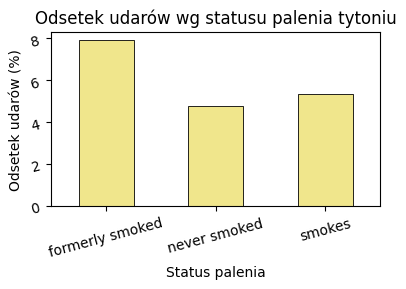

In [23]:
#  bez kategorii "Unknown" 
df_smoke = df[df['smoking_status'] != 'Unknown'].copy()

# tabela kontyngencji
contingency = pd.crosstab(df_smoke['smoking_status'], df_smoke['stroke'])
print("Tabela kontyngencji: palenie vs. udar")
print(contingency)

chi2, p_chi2, dof, expected = stats.chi2_contingency(contingency)

expected_df = pd.DataFrame(expected.round(1), index=contingency.index, columns=contingency.columns)
print("\nOczekiwane liczebności:")
print(expected_df)

print(f"\nStatystyka Chi2 = {chi2:.4f}")
print(f"Stopnie swobody: {dof}")
print(print_result(p_chi2))

# Wykres: Odsetek udarów wg statusu palenia
stroke_rate = df_smoke.groupby('smoking_status')['stroke'].mean() * 100

fig, ax = plt.subplots(figsize=(4, 3))
stroke_rate.plot(kind='bar',color='khaki', edgecolor='black', linewidth=0.6, ax=ax)
ax.set_ylabel("Odsetek udarów (%)")
ax.set_title("Odsetek udarów wg statusu palenia tytoniu")
ax.set_xlabel("Status palenia")
ax.tick_params(rotation=15)
plt.tight_layout()
plt.show()

Wszystkie oczekiwane liczebności przekraczają wartość 5, co potwierdza poprawność zastosowania testu chi-kwadrat. <br>
Wartość p-value = ~0,0032 jest poniżej przyjętego poziomu istotności alpha=0,05, zatem hipoteza zerowa H0 zostaje odrzucona. Istnieje statystycznie istotna zależność między statusem palenia tytoniu a wystąpieniem udaru mózgu. <br>
Porównując liczebności zaobserwowane z oczekiwanymi, widać że grupa byłych palaczy (formerly smoked) wykazuje wyraźnie więcej udarów niż wynikałoby z założenia o niezależności (70 vs 50,1 oczekiwanych), natomiast grupa nigdy niepalących (never smoked) ma mniej udarów niż oczekiwano (90 vs 107,2). Grupa aktualnych palaczy (smokes) nie odbiega istotnie od wartości oczekiwanych (42 vs 44,7).<br>
Należy jednak zachować ostrożność w interpretacji, ponieważ wyższa częstość udarów wśród byłych palaczy może wynikać z wyższego wieku tej grupy, a nie bezpośrednio z historii palenia. Test chi-kwadrat stwierdza jedynie istnienie zależności, nie pozwala natomiast wnioskować o jej przyczynie. Dodatkowo z analizy wykluczono kategorię Unknown, co stanowi ograniczenie wyników.

### Test 4: Levene'a - jednorodność wariancji poziomu glukozy
Test założeń przed ANOVA.<br>

Hipotezy:
- H0​: Wariancje poziomu glukozy są jednorodne we wszystkich grupach zawodowych (homoskedastyczność)
- H1​: Co najmniej jedna z grup ma istotnie różną wariancję
Poziom istotności: alpha=0,05

In [24]:
groups_glucose = [
    df[df['work_type'] == wt]['avg_glucose_level'].values
    for wt in ['Govt_job', 'Private', 'Self-employed', 'children', 'Never_worked']
]
group_labels = ['Govt_job', 'Private', 'Self-employed', 'children', 'Never_worked']

print("Wariancje w grupach:")
for label, gr in zip(group_labels, groups_glucose):
    print(f"{label}: {np.var(gr, ddof=1):.2f}, (n={len(gr)})")

stat_lev, p_lev = levene(*groups_glucose)
print(f"\nStatystyka Levene'a = {stat_lev:.4f}")
print(print_result(p_lev))

Wariancje w grupach:
Govt_job: 2275.02, (n=657)
Private: 2105.80, (n=2924)
Self-employed: 2674.91, (n=819)
children: 710.70, (n=687)
Never_worked: 823.53, (n=22)

Statystyka Levene'a = 21.4626
p = 0.000000 < alpha = 0.05 -> odrzucenie H0


Wartość p-value jest znacznie poniżej przyjętego poziomu istotności alpha=0,05, zatem hipoteza zerowa H0 o jednorodności wariancji zostaje odrzucona. Wariancje poziomu glukozy różnią się istotnie między grupami zawodowymi. Największą wariancję odnotowano w grupie Self-employed (2674,91), co wskazuje na duże zróżnicowanie poziomu glukozy wśród osób samozatrudnionych. Najmniejszą wariancją charakteryzują się grupy children (710,70) oraz Never_worked (823,53).<br>
Ze względu na bardzo małą liczebność grupy Never_worked (n=22) sprawdzono również jednorodność wariancji po jej wykluczeniu. Wynik pozostał bez zmian - hipoteza zerowa została odrzucona również dla czterech grup, co potwierdza że wynik nie jest spowodowanym małą liczebnością tej grupy. <br>
Niespełnienie założenia jednorodności wariancji oznacza, że klasyczna ANOVA może nie być w pełni odpowiednia.

## 6. Bootstrap
Metoda bootstrapowa polega na wielokrotnym losowaniu ze zwracaniem z próby i obliczaniu statystyki. Pozwala wyznaczyć przedział ufności bez założeń o rozkładzie populacji.

**Bootstrap dla średniej poziomu glukozy**

Bootstrap: średnia poziomu glukozy
Estymowana średnia: 106.1404 mg/dL
Przedział ufności bootstrapowy (95%): (104.8850; 107.3731)
Przedział ufności klasyczny (95%): (104.8986; 107.3822)


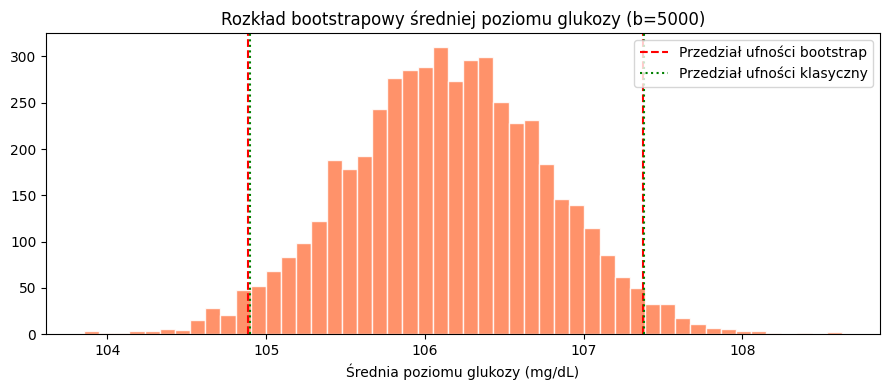

In [25]:
np.random.seed(42)
b = 5000  # liczba próbek bootstrapowych

glucose = df['avg_glucose_level'].values
n = len(glucose)

bootstrap_means = np.zeros(b)
for i in range(b):
    sample = np.random.choice(glucose, size=n, replace=True)
    bootstrap_means[i] = np.mean(sample)

# bootstrapowy przedział ufności (metoda percentylowa)
ci_boot_mean = (np.quantile(bootstrap_means, 0.025), np.quantile(bootstrap_means, 0.975))

# klasyczny przedział ufności (metoda normalna, n duże)
ci_classic_mean = stats.norm.interval(0.95, loc=np.mean(glucose), scale=stats.sem(glucose))

print("Bootstrap: średnia poziomu glukozy")
print(f"Estymowana średnia: {np.mean(glucose):.4f} mg/dL")
print(f"Przedział ufności bootstrapowy (95%): ({ci_boot_mean[0]:.4f}; {ci_boot_mean[1]:.4f})")
print(f"Przedział ufności klasyczny (95%): ({ci_classic_mean[0]:.4f}; {ci_classic_mean[1]:.4f})")


fig, ax = plt.subplots(figsize=(9, 4))
ax.hist(bootstrap_means, bins=50, color='coral', edgecolor='white', alpha=0.85)
ax.axvline(ci_boot_mean[0], color='red', linestyle='--', linewidth=1.5, label='Przedział ufności bootstrap')
ax.axvline(ci_boot_mean[1], color='red', linestyle='--', linewidth=1.5)
ax.axvline(ci_classic_mean[0], color='green', linestyle=':', linewidth=1.5, label='Przedział ufności klasyczny')
ax.axvline(ci_classic_mean[1], color='green', linestyle=':', linewidth=1.5)
ax.set_xlabel("Średnia poziomu glukozy (mg/dL)")
ax.set_title("Rozkład bootstrapowy średniej poziomu glukozy (b=5000)")
ax.legend()
plt.tight_layout()
plt.show()


Estymowana średnia poziomu glukozy wynosi 106,14 mg/dL. Na podstawie 5000 próbek bootstrapowych wyznaczono 95% przedział ufności metodą percentylową: (104,8850; 107,3731) mg/dL. <br>
Bootstrapowy i klasyczny przedział ufności są niemal identyczne (różnica rzędu 0,01 mg/dL). Wynika to z dużej liczebności próby (n=5109) - przy tak dużym n rozkład średniej próbkowej jest bliski normalnemu przez co obie metody dają praktycznie ten sam wynik. <br>
Rozkład bootstrapowy widoczny na histogramie ma kształt zbliżony do symetrycznego dzwonu. Bootstrap nie wnosi tu istotnej poprawki względem metody klasycznej.

## 7. Jednoczynnikowa analiza wariancji (ANOVA) 
Pytanie badawcze nr 3: *Czy średni poziom glukozy (avg_glucose_level) we krwi różni się istotnie pomiędzy grupami zawodowymi (work_type)*? <br>

Hipotezy:
- H0​: Średni poziom glukozy jest jednakowy we wszystkich grupach zawodowych: μ1​=μ2​=μ3​=μ4​=μ5​
- H1​: Co najmniej jedna grupa zawodowa różni się średnim poziomem glukozy
Poziom istotności: alpha=0,05

**Grupy porównawcze**

In [26]:
group_names = ['Govt_job', 'Private', 'Self-employed', 'children', 'Never_worked']
groups = [df[df['work_type'] == wt]['avg_glucose_level'].values for wt in group_names]

print(group_names)

['Govt_job', 'Private', 'Self-employed', 'children', 'Never_worked']


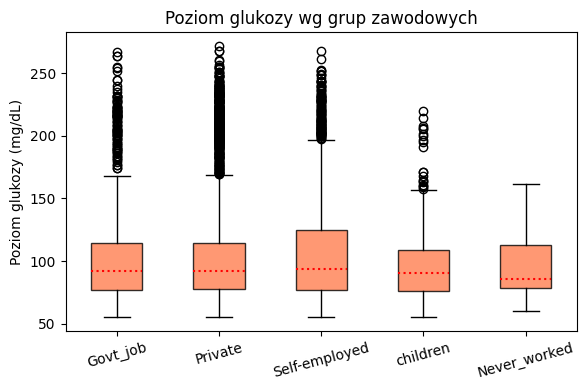

In [27]:
fig, ax = plt.subplots(figsize=(6, 4))
ax.boxplot(groups, tick_labels=group_names, patch_artist=True, 
                boxprops=dict(facecolor='coral', alpha=0.8),
                medianprops={"color": "red", "linestyle":':', "linewidth":1.5})
ax.set_title("Poziom glukozy wg grup zawodowych")
ax.set_ylabel("Poziom glukozy (mg/dL)")
ax.tick_params(axis='x', rotation=15)
plt.tight_layout()
plt.show()

**Sprawdzenie założeń ANOVA**

**Założenie 1:** Normalność rozkładu w każdej grupie (Shapiro-Wilk)<br>
Hipotezy:
- H0​: Rozkład średniej wartości glukozy w grupie jest normalny
- H1​: Rozkład średniej wartości glukozy w grupie nie jest normalny
Poziom istotności: alpha=0,05

In [28]:
np.random.seed(42)
for name, g in zip(group_names, groups):
    sample = np.random.choice(g, size=min(len(g), 200), replace=False)
    stat, p = shapiro(sample)
    print(f"{name} (n={len(g)}): W={stat:.4f}, {print_result(p)}")

Govt_job (n=657): W=0.7929, p = 0.000000 < alpha = 0.05 -> odrzucenie H0
Private (n=2924): W=0.8031, p = 0.000000 < alpha = 0.05 -> odrzucenie H0
Self-employed (n=819): W=0.8092, p = 0.000000 < alpha = 0.05 -> odrzucenie H0
children (n=687): W=0.9148, p = 0.000000 < alpha = 0.05 -> odrzucenie H0
Never_worked (n=22): W=0.9209, p = 0.079257 >= alpha = 0.05 -> brak podstaw do odrzucenia H0


Test Shapiro-Wilka wykazał brak normalności rozkładu poziomu glukozy we wszystkich grupach z wyjątkiem Never_worked. W czterech głównych grupach (Govt_job, Private, Self-employed, children) p-value = ~0,0000 < 0,05, co oznacza odrzucenie hipotezy H0 o normalności. Wartości statystyki W są poniżej 1 (zakres 0,79-0,91), co wskazuje na istotne odchylenie od rozkładu normalnego - zgodnie z obserwacją z analizy opisowej, rozkład glukozy jest prawostronnie asymetryczny.
Jedynie w grupie Never_worked nie ma podstaw do odrzucenia hipotezy o normalności, jednak grupa liczy zaledwie n=22 obserwacje, przez co test ma bardzo małą moc i może nie wykryć odchylenia od normalności nawet gdy ono istnieje.

-> założenie normalności nie jest spełnione 

**Założenie 2:** Jednorodność wariancji (Levene) <br>
Jednorodność wariancji sprawdzono testem Levene'a w sekcji 5 (Test 4).<br>
Wynik: statystyka Levene'a = ~21.46, p = ~0.0000 -> H0 odrzucona. <br>Wariancje poziomu glukozy nie są jednorodne między grupami zawodowymi.

-> założenie jednorodności wariancji nie jest spełnione


Ponieważ założenie normalności nie jest spełnione w żadnej z istotnych grup, a w sekcji 5 wykazano również brak jednorodności wariancji, oba kluczowe założenia ANOVA są naruszone. W związku z tym główną analizą będzie nieparametryczny test Kruskala-Wallisa, natomiast ANOVA zostanie przeprowadzona jako punkt odniesienia umożliwiający porównanie wyników obu podejść.

In [29]:
# ANOVA
stat_anova, p_anova = f_oneway(*groups)
print("Test ANOVA")
print(f"Statystyka F = {stat_anova:.4f}")
print(f"p = {p_anova:.6f}")
print(f"{print_result(p_anova)}\n")

# Kruskal-Wallis
stat_kw, p_kw = kruskal(*groups)
print("Test Kruskala-Wallisa")
print(f"Statystyka H = {stat_kw:.4f}")
print(f"p = {p_kw:.6f}")
print(f"{print_result(p_kw)}\n")


Test ANOVA
Statystyka F = 16.6053
p = 0.000000
p = 0.000000 < alpha = 0.05 -> odrzucenie H0

Test Kruskala-Wallisa
Statystyka H = 17.2978
p = 0.001692
p = 0.001692 < alpha = 0.05 -> odrzucenie H0



Oba testy zgodnie wskazują na odrzucenie hipotezy zerowej przy poziomie istotności alpha=0,05.<br>
Test ANOVA dał statystykę F = 16,61 przy p = ~0,0000, natomiast nieparametryczny test Kruskala-Wallisa statystykę H = 17,30 przy p = ~0,0017. Oznacza to, że istnieje statystycznie istotna różnica w poziomie glukozy między co najmniej jedną parą grup zawodowych. <br>
Ponieważ założenia ANOVA nie są spełnione, wynik testu Kruskala-Wallisa jest miarodajny i stanowi właściwą podstawę do wnioskowania -> różnice między grupami są statystycznie istotne.<br>
Samo odrzucenie H0​ nie wskazuje które konkretnie grupy się różnią, dlatego w tym celu przeprowadzono test post-hoc Dunna

**Test post-hoc Dunna** - sprawdzenie które pary grup różnią się istotnie<br>
Dla nierównolicznych grup z nierównymi wariancjami zalecane są testy C Dunnetta lub T2 Tamhane'a. Testy te nie posiadają jednak gotowej implementacji w standardowych bibliotekach Pythona, z tego względu zastosowano test Dunna - nieparametryczny test post-hoc. Dodatkowo, ponieważ główną analizą był nieparametryczny test Kruskala-Wallisa (ze względu na niespełnienie założeń normalności i jednorodności wariancji), test Dunna jest odpowidnim wyborem - nie wymaga normalności rozkładu ani jednorodności wariancji. 
Wartości p-value skorygowano metodą Bonferroniego.

Test post-hoc Dunna
Macierz p-wartości (skorygowane metodą Bonferroniego):

               Govt_job  Never_worked  Private  Self-employed  children
Govt_job         1.0000           1.0   1.0000         1.0000    0.0969
Never_worked     1.0000           1.0   1.0000         1.0000    1.0000
Private          1.0000           1.0   1.0000         1.0000    0.0059
Self-employed    1.0000           1.0   1.0000         1.0000    0.0007
children         0.0969           1.0   0.0059         0.0007    1.0000


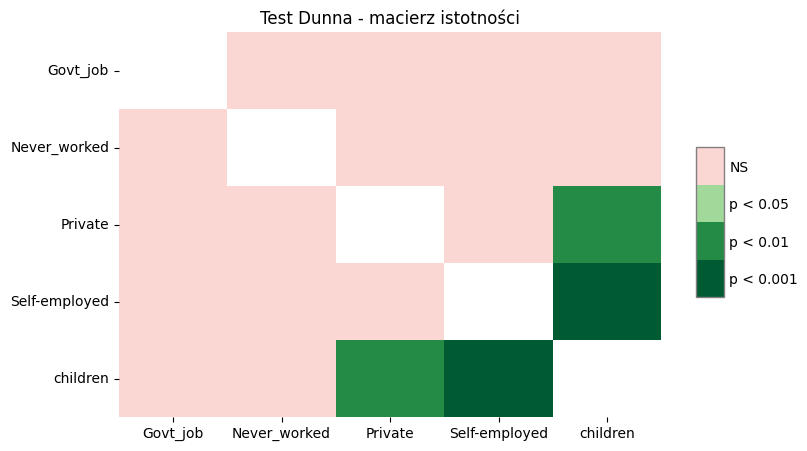

In [44]:
import scikit_posthocs as sp

dunn = sp.posthoc_dunn(
    df,
    val_col='avg_glucose_level',
    group_col='work_type',
    p_adjust='bonferroni'  # poprawka Bonferroniego na wielokrotne porównania
)

print("Test post-hoc Dunna")
print("Macierz p-wartości (skorygowane metodą Bonferroniego):\n")
print(dunn.round(4))

fig, ax = plt.subplots(figsize=(7, 5))
sp.sign_plot(dunn, ax=ax)
ax.set_title("Test Dunna - macierz istotności")
plt.show()

Test post-hoc Dunna wskazał, że spośród kilku porównywanych par grup 2 różnią się istotnie statystycznie (p < 0,05):

- **Private vs children** (p = 0,0059) - pracownicy sektora prywatnego mają istotnie wyższy średni poziom glukozy niż dzieci
- **Self-employed vs children** (p = 0,0007) - osoby samozatrudnione mają istotnie wyższy średni poziom glukozy niż dzieci

Różnica **Govt_job vs children** (p = 0,0969) nie osiągnęła progu istotności po korekcie Bonferroniego, choć jest bliska granicy - co może wynikać z surowości tej poprawki przy większej liczbie porównań. Pozostałe pary, w tym wszystkie porównania z grupą Never_worked, nie wykazują istotnych różnic, co w przypadku tej grupy może wynikać z bardzo małej liczebności (n=22).

Wspólny wzorzec: grupa children wyróżnia się najniższym poziomem glukozy. Jest to biologicznie uzasadnione - dzieci mają zazwyczaj niższy poziom glukozy i znacznie niższe ryzyko cukrzycy niż dorośli.

## 8. Wnioski końcowe

**Odpowiedzi na pytania badawcze:**

1. *Czy średni wiek pacjentów z udarem mózgu istotnie różni się od średniego wieku pacjentów bez udaru?*

Test Manna-Whitneya wykazał statystycznie istotną różnicę w rozkładzie wieku między grupami (p ≈ 0,0000). Mediana wieku pacjentów z udarem wynosi ~71 lat, wobec ~43 lat w grupie bez udaru. 


2. *Czy istnieje statystycznie istotna zależność między paleniem tytoniu a wystąpieniem udaru mózgu?*

Test chi-kwadrat wykazał istotną zależność (Chi2 = 11,49, p = ~0,0032). Największe odchylenie od niezależności zaobserwowano w grupie byłych palaczy. Interpretację ogranicza jednak wykluczenie kategorii Unknown (30,2% obserwacji).


3. *Czy średni poziom glukozy (avg_glucose_level) we krwi różni się istotnie pomiędzy grupami zawodowymi?*

Nieparametryczny test Kruskala-Wallisa (H = 17,30, p = ~0,0017) potwierdza istnienie istotnych różnic. Test post-hoc Dunna (zastosowany jako nieparametryczna kontynuacja Kruskala-Wallisa) wskazał, że istotnie niższy poziom glukozy wykazuje grupa children w porównaniu z pracownikami sektora prywatnego (p = ~0,006) oraz osobami samozatrudnionymi (p = 0,0007). Różnice te są biologicznie uzasadnione - dzieci mają zazwyczaj niższy poziom glukozy i znacznie niższe ryzyko cukrzycy niż dorośli.

4. *Jaki jest przedział ufności dla odsetka pacjentów z udarem mózgu?*

Estymowany odsetek udarów wynosi 4,87%, a 95% przedział ufności (metoda Wilsona) to (4,32% ; 5,50%). Przedział jest wąski, co świadczy o dużej precyzji estymacji przy n = 5109.


**Najważniejsze wyniki:**
<br>Spośród wszystkich analizowanych czynników wiek okazał się wyraźnie związany z ryzykiem udaru - różnica median wynosząca niemal 28 lat między grupami jest zarówno statystycznie istotna jak i klinicznie znacząca. Poziom glukozy również różni się istotnie między pacjentami z udarem (średnia ~132 mg/dL) a bez udaru (średnia ~105 mg/dL), co potwierdza rolę cukrzycy jako czynnika ryzyka. Metoda bootstrapowa dla średniego poziomu glukozy dała wyniki niemal identyczne z metodą klasyczną, co potwierdza stabilność estymacji przy dużej próbie.

**Możliwe dalsze kierunki badań:**
- Przeprowadzenie wieloczynnikowej analizy (np. regresja logistyczna) uwzględniającej jednocześnie wiek, poziom glukozy, bmi, płeć, nadciśnienie i palenie.
- Zbadanie związku palenia z udarem z kontrolą wieku - zaobserwowana zależność w teście chi-kwadrat może być częściowo artefaktem różnic wiekowych między grupami, a nie bezpośrednim efektem palenia.
- Analiza interakcji między nadciśnieniem a wiekiem - oba czynniki są silnie związane z udarem, a ich łączny efekt mógłby być silniejszy.
